EXPLORE THE DATASET

In [1]:
#import imp libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#load dataset
df = pd.read_csv('/content/drive/MyDrive/Mini Project/M1_final.csv')

print("Dataset shape:", df.shape)

Dataset shape: (28820, 23)


In [3]:
print(df.head())

   MONTH  DAY_OF_MONTH  DAY_OF_WEEK OP_UNIQUE_CARRIER TAIL_NUM DEST  \
0     11             1            5                B6   N828JB  CHS   
1     11             1            5                B6   N992JB  LAX   
2     11             1            5                B6   N959JB  FLL   
3     11             1            5                B6   N999JQ  MCO   
4     11             1            5                DL   N880DN  ATL   

   DEP_DELAY  CRS_ELAPSED_TIME  DISTANCE  CRS_DEP_M  ...  Dew Point  Humidity  \
0         -1               124       636        324  ...         34        58   
1         -7               371      2475        340  ...         34        58   
2         40               181      1069        301  ...         34        58   
3         -2               168       944        345  ...         34        58   
4         -4               139       760        360  ...         32        58   

   Wind Wind Speed  Wind Gust Pressure     Condition  sch_dep  sch_arr  \
0     W     

In [4]:
print(df.info())
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28820 entries, 0 to 28819
Data columns (total 23 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   MONTH              28820 non-null  int64  
 1   DAY_OF_MONTH       28820 non-null  int64  
 2   DAY_OF_WEEK        28820 non-null  int64  
 3   OP_UNIQUE_CARRIER  28820 non-null  object 
 4   TAIL_NUM           28820 non-null  object 
 5   DEST               28820 non-null  object 
 6   DEP_DELAY          28820 non-null  int64  
 7   CRS_ELAPSED_TIME   28820 non-null  int64  
 8   DISTANCE           28820 non-null  int64  
 9   CRS_DEP_M          28820 non-null  int64  
 10  DEP_TIME_M         28820 non-null  int64  
 11  CRS_ARR_M          28820 non-null  int64  
 12  Temperature        28820 non-null  int64  
 13  Dew Point          28820 non-null  object 
 14  Humidity           28820 non-null  int64  
 15  Wind               28818 non-null  object 
 16  Wind Speed         288

In [5]:
print(df.isnull().sum())

MONTH                0
DAY_OF_MONTH         0
DAY_OF_WEEK          0
OP_UNIQUE_CARRIER    0
TAIL_NUM             0
DEST                 0
DEP_DELAY            0
CRS_ELAPSED_TIME     0
DISTANCE             0
CRS_DEP_M            0
DEP_TIME_M           0
CRS_ARR_M            0
Temperature          0
Dew Point            0
Humidity             0
Wind                 2
Wind Speed           0
Wind Gust            0
Pressure             0
Condition            0
sch_dep              0
sch_arr              0
TAXI_OUT             0
dtype: int64


In [6]:
print(df.duplicated().sum())

0


In [7]:
print(df.columns)

Index(['MONTH', 'DAY_OF_MONTH', 'DAY_OF_WEEK', 'OP_UNIQUE_CARRIER', 'TAIL_NUM',
       'DEST', 'DEP_DELAY', 'CRS_ELAPSED_TIME', 'DISTANCE', 'CRS_DEP_M',
       'DEP_TIME_M', 'CRS_ARR_M', 'Temperature', 'Dew Point', 'Humidity',
       'Wind', 'Wind Speed', 'Wind Gust', 'Pressure', 'Condition', 'sch_dep',
       'sch_arr', 'TAXI_OUT'],
      dtype='object')


In [8]:
print("\nSummary Statistics:\n", df.describe())


Summary Statistics:
               MONTH  DAY_OF_MONTH   DAY_OF_WEEK     DEP_DELAY  \
count  28820.000000  28820.000000  28820.000000  28820.000000   
mean       7.894240     16.021096      4.008952      6.374983   
std        4.991723      8.750179      1.985230     38.735144   
min        1.000000      1.000000      1.000000    -22.000000   
25%        1.000000      8.000000      2.000000     -6.000000   
50%       11.000000     16.000000      4.000000     -3.000000   
75%       12.000000     24.000000      6.000000      2.000000   
max       12.000000     31.000000      7.000000   1276.000000   

       CRS_ELAPSED_TIME      DISTANCE     CRS_DEP_M    DEP_TIME_M  \
count      28820.000000  28820.000000  28820.000000  28820.000000   
mean         225.288203   1267.746079    831.003851    828.934698   
std          119.482417    889.343246    299.398525    305.864103   
min           57.000000     94.000000    301.000000      1.000000   
25%          124.000000    483.000000    545.00

In [9]:
# Unique values for categorical columns
cat_cols = df.select_dtypes(include=["object"]).columns
for col in cat_cols:
    print(f"\nUnique values in {col}:")
    print(df[col].unique()[:10])  # show only first 10 unique values


Unique values in OP_UNIQUE_CARRIER:
['B6' 'DL' 'AA' 'AS' 'MQ' '9E' 'YX' 'HA' 'OO']

Unique values in TAIL_NUM:
['N828JB' 'N992JB' 'N959JB' 'N999JQ' 'N880DN' 'N983NN' 'N107NN' 'N274JB'
 'N663JB' 'N283JB']

Unique values in DEST:
['CHS' 'LAX' 'FLL' 'MCO' 'ATL' 'ORD' 'BUF' 'LGB' 'LAS' 'DCA']

Unique values in Dew Point:
['34' '32' '33' '31' '30' '29' '67' '35' '36' '38']

Unique values in Wind:
['W' 'WNW' 'NW' 'NNW' 'S' 'ENE' 'NE' 'NNE' 'E' 'SE']

Unique values in Condition:
['Fair / Windy' 'Fair' 'Light Rain / Windy' 'Partly Cloudy'
 'Mostly Cloudy' 'Cloudy' 'Light Rain' 'Mostly Cloudy / Windy'
 'Partly Cloudy / Windy' 'Light Snow / Windy']


In [10]:
#target feature for classification

df["DELAYED"] = (df["DEP_DELAY"] > 5).astype(int)


In [11]:
# Classification Target
target_class = 'DELAYED'

# Regression Target
target_reg = 'DEP_DELAY'

# Features
X = df.drop([target_class, target_reg], axis=1)

# Targets
y_class = df[target_class]
y_reg = df[target_reg]

print("Target features selected successfully!")


Target features selected successfully!


preprocessing

In [12]:
# 1️⃣ Check for missing values
print("Missing Values Before Imputation:\n")
print(df.isnull().sum())
print("-" * 50)

# 2️⃣ Handle missing values

# Numeric columns → fill with median (robust to outliers)
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
for col in num_cols:
    median_value = df[col].median()
    df[col].fillna(median_value, inplace=True)

# Categorical columns → fill with mode (most frequent value)
cat_cols = df.select_dtypes(include=['object']).columns
for col in cat_cols:
    mode_value = df[col].mode()[0]
    df[col].fillna(mode_value, inplace=True)

# 3️⃣ Confirm missing values handled
print("\nMissing Values After Imputation:\n")
print(df.isnull().sum())


Missing Values Before Imputation:

MONTH                0
DAY_OF_MONTH         0
DAY_OF_WEEK          0
OP_UNIQUE_CARRIER    0
TAIL_NUM             0
DEST                 0
DEP_DELAY            0
CRS_ELAPSED_TIME     0
DISTANCE             0
CRS_DEP_M            0
DEP_TIME_M           0
CRS_ARR_M            0
Temperature          0
Dew Point            0
Humidity             0
Wind                 2
Wind Speed           0
Wind Gust            0
Pressure             0
Condition            0
sch_dep              0
sch_arr              0
TAXI_OUT             0
DELAYED              0
dtype: int64
--------------------------------------------------

Missing Values After Imputation:

MONTH                0
DAY_OF_MONTH         0
DAY_OF_WEEK          0
OP_UNIQUE_CARRIER    0
TAIL_NUM             0
DEST                 0
DEP_DELAY            0
CRS_ELAPSED_TIME     0
DISTANCE             0
CRS_DEP_M            0
DEP_TIME_M           0
CRS_ARR_M            0
Temperature          0
Dew Point      

/tmp/ipython-input-2766277047.py:12: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(median_value, inplace=True)
/tmp/ipython-input-2766277047.py:18: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 

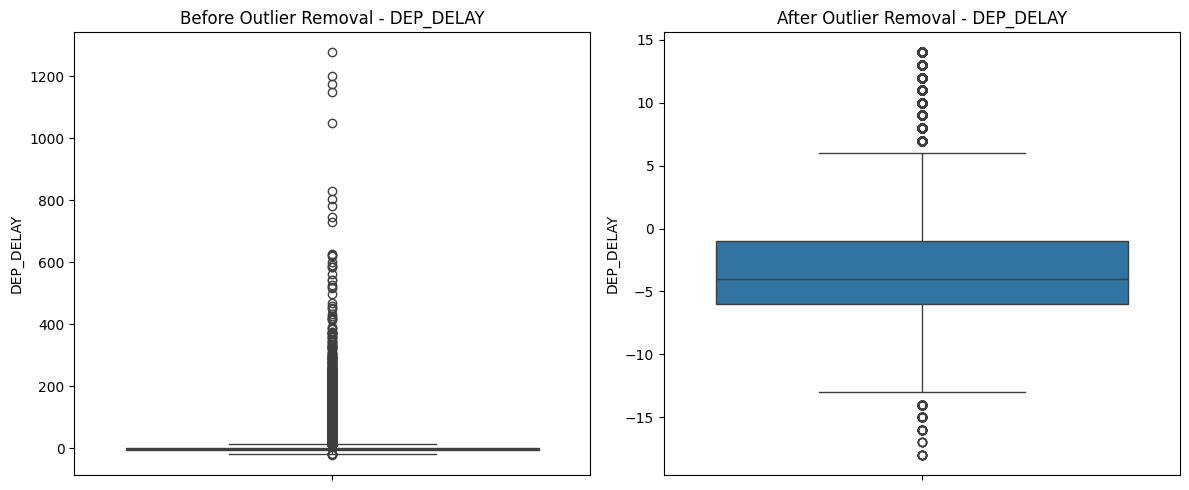

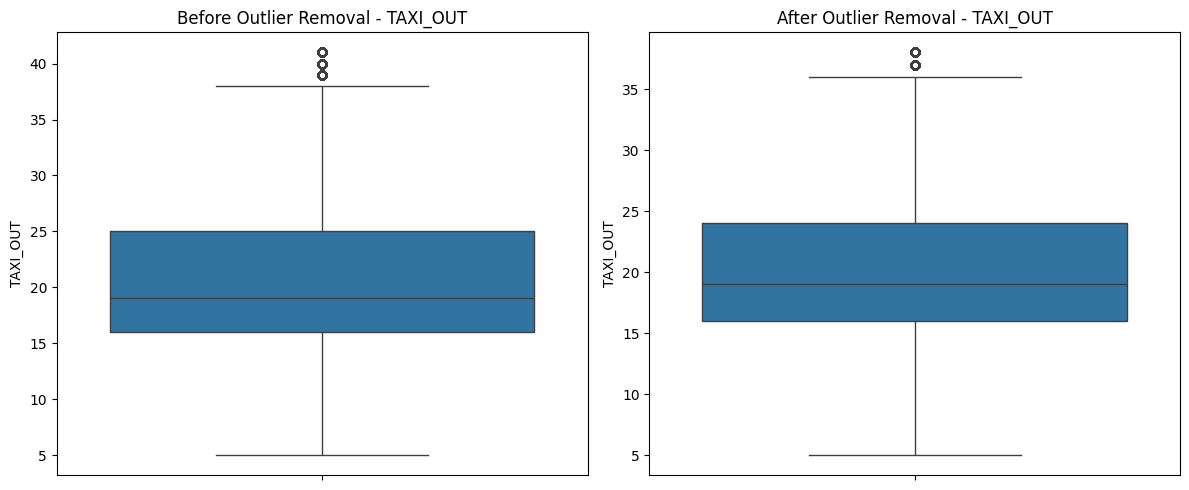

In [20]:
df_before = df.copy()
def remove_outliers(data, col):
    q1 = data[col].quantile(0.25)
    q3 = data[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return data[(data[col] >= lower) & (data[col] <= upper)]

df_after = df_before.copy()
df_after = remove_outliers(df_after, 'DEP_DELAY')
df_after = remove_outliers(df_after, 'TAXI_OUT')

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12,5))

# BEFORE
plt.subplot(1,2,1)
sns.boxplot(y=df_before['DEP_DELAY'])
plt.title("Before Outlier Removal - DEP_DELAY")

# AFTER
plt.subplot(1,2,2)
sns.boxplot(y=df_after['DEP_DELAY'])
plt.title("After Outlier Removal - DEP_DELAY")

plt.tight_layout()
plt.show()


plt.figure(figsize=(12,5))

# BEFORE
plt.subplot(1,2,1)
sns.boxplot(y=df_before['TAXI_OUT'])
plt.title("Before Outlier Removal - TAXI_OUT")

# AFTER
plt.subplot(1,2,2)
sns.boxplot(y=df_after['TAXI_OUT'])
plt.title("After Outlier Removal - TAXI_OUT")

plt.tight_layout()
plt.show()



In [22]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder

print("Feature engineering...")

# -----------------------------
# 1️⃣ FEATURE ENGINEERING
# -----------------------------

# Departure hour (CRS_DEP_M is minutes since midnight)
df['DEP_HOUR'] = (df['CRS_DEP_M'] // 60).astype(int)

# Weekend flag
df['IS_WEEKEND'] = df['DAY_OF_WEEK'].isin([6, 7]).astype(int)

# Route feature: airline-destination combination
df['ROUTE'] = df['OP_UNIQUE_CARRIER'].astype(str) + '-' + df['DEST'].astype(str)

# Time slot: day + hour combination
df['TIME_SLOT'] = df['DAY_OF_WEEK'].astype(str) + '-' + df['DEP_HOUR'].astype(str)

# Convert Dew Point to numeric if needed
df["Dew Point"] = df["Dew Point"].astype(float)

# -----------------------------
# 2️⃣ DROP UNNECESSARY COLUMNS
# -----------------------------

cols_to_drop = ["TAIL_NUM", "Wind Gust", "MONTH"]
df = df.drop(columns=[c for c in cols_to_drop if c in df.columns])

# -----------------------------
# 3️⃣ ENCODE CATEGORICAL FEATURES
# -----------------------------
cat_cols = ["OP_UNIQUE_CARRIER", "DEST", "Wind", "Condition", "ROUTE", "TIME_SLOT"]

# Only keep categorical columns that exist
cat_cols = [c for c in cat_cols if c in df.columns]

le_dict = {}

for col in cat_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col].astype(str))
    le_dict[col] = le   # Save encoder if needed later

# -----------------------------
# 4️⃣ DONE — PREVIEW CLEANED DATA
# -----------------------------
print("Preprocessing complete!")
print("Final dataset shape:", df.shape)
df.head()


Feature engineering...
Preprocessing complete!
Final dataset shape: (28820, 25)


,DAY_OF_MONTH,DAY_OF_WEEK,OP_UNIQUE_CARRIER,DEST,DEP_DELAY,CRS_ELAPSED_TIME,DISTANCE,CRS_DEP_M,DEP_TIME_M,CRS_ARR_M,...,Pressure,Condition,sch_dep,sch_arr,TAXI_OUT,DELAYED,DEP_HOUR,IS_WEEKEND,ROUTE,TIME_SLOT
0,1,5,3,10,-1,124,636,324,323,448,...,29.86,4,9,17,14,0,5,0,55,90
1,1,5,3,28,-7,371,2475,340,333,531,...,29.86,4,9,17,15,0,5,0,61,90
2,1,5,3,20,40,181,1069,301,341,482,...,29.86,4,9,17,22,1,5,0,57,90
3,1,5,3,30,-2,168,944,345,343,513,...,29.86,4,9,17,12,0,5,0,63,90
4,1,5,4,1,-4,139,760,360,356,499,...,29.91,4,9,17,13,0,6,0,89,91


visualization

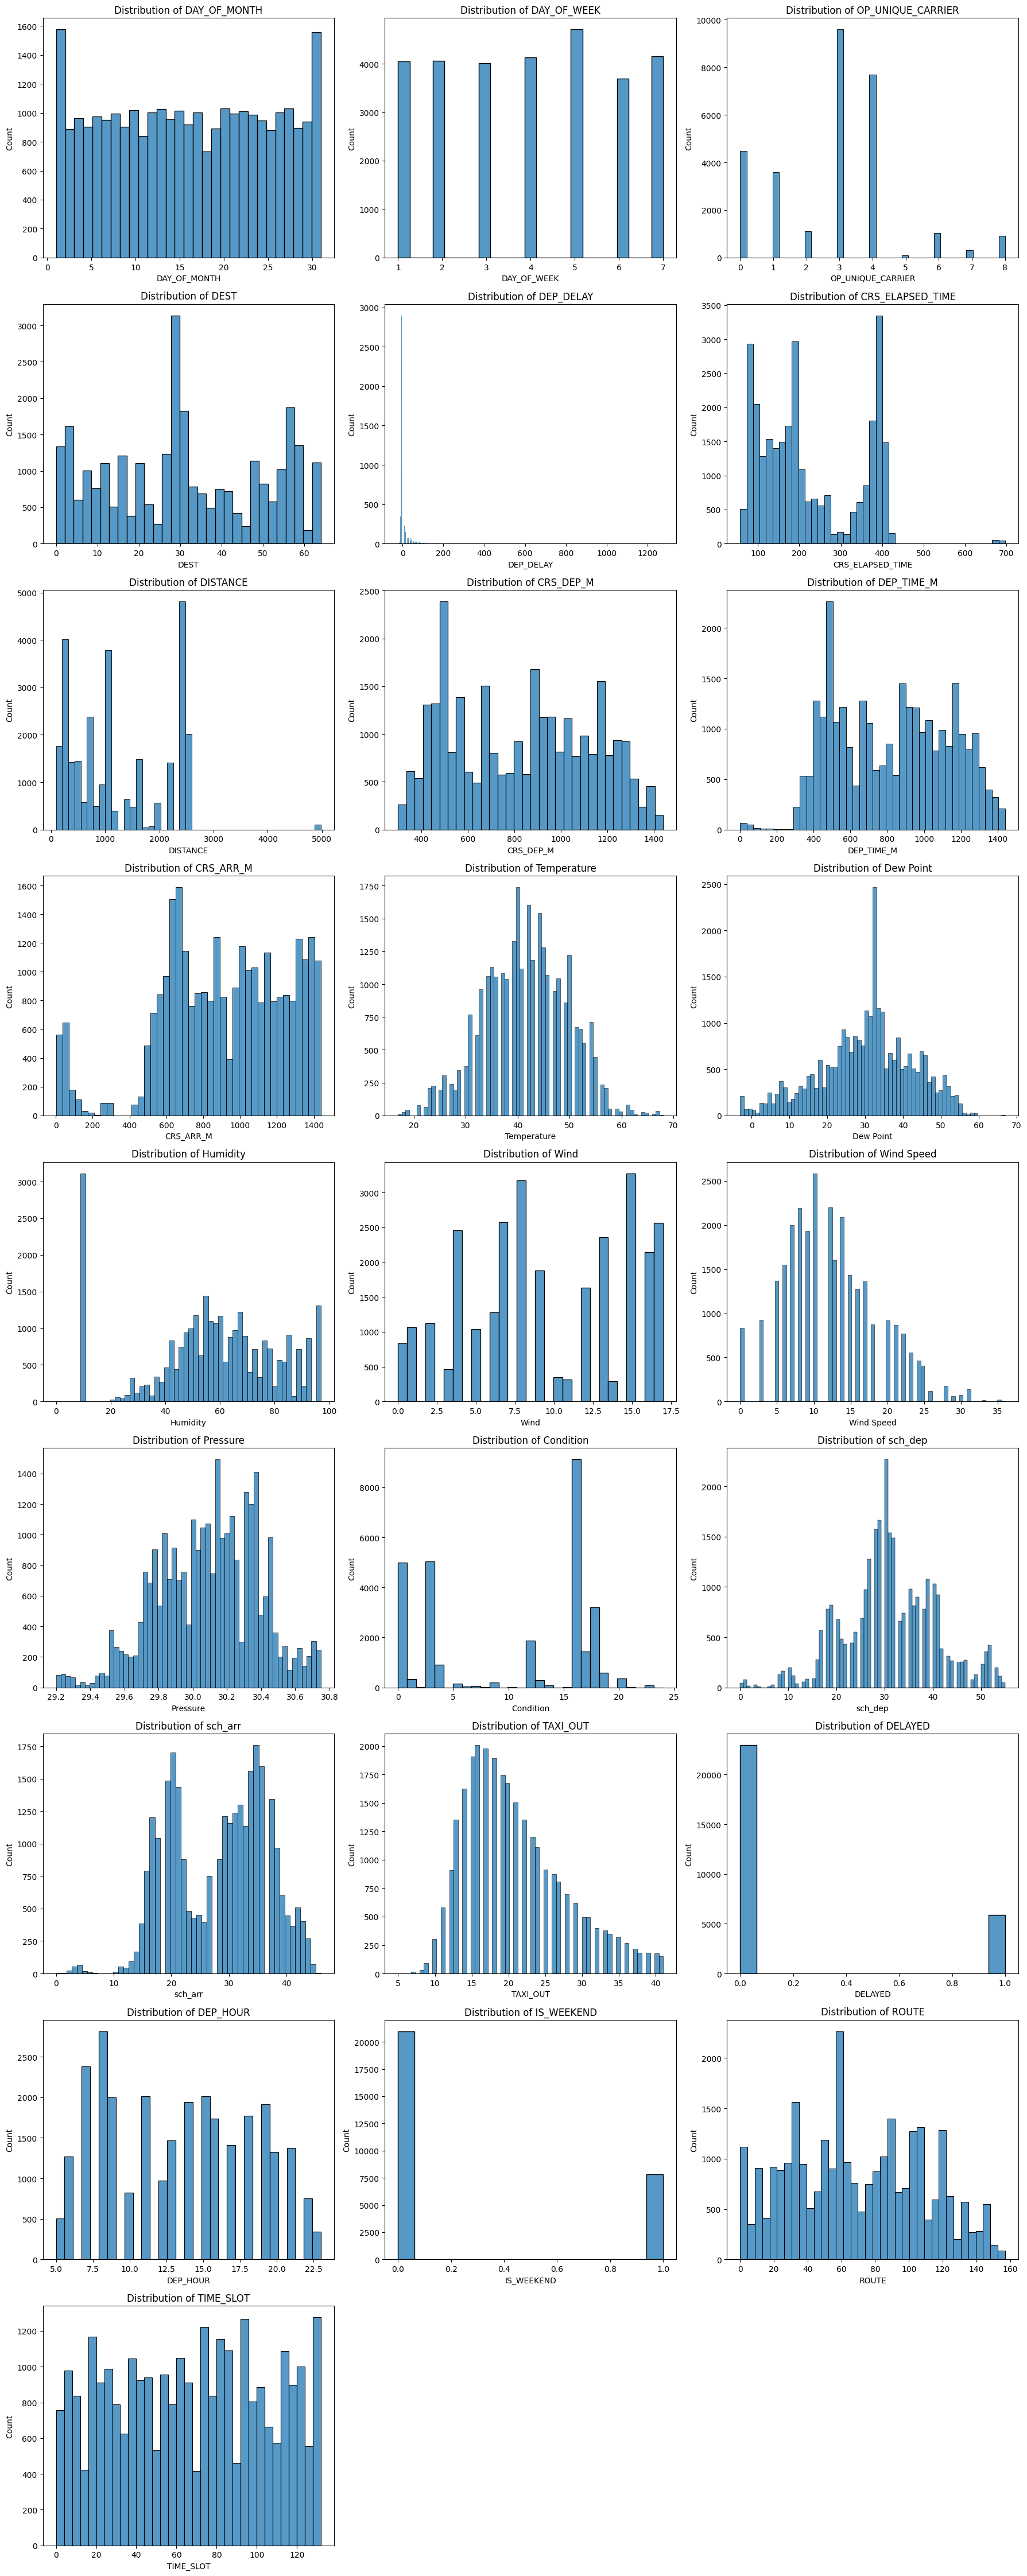

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select only numeric columns
num_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Plot grid size based on number of columns
n_cols = 3
n_rows = (len(num_cols) + n_cols - 1) // n_cols

plt.figure(figsize=(18, 5 * n_rows))

for i, col in enumerate(num_cols, 1):
    plt.subplot(n_rows, n_cols, i)
    sns.histplot(df[col], kde=False)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")

plt.tight_layout()
plt.show()


DELAYED
0    22944
1     5876
Name: count, dtype: int64

Percentage distribution:
DELAYED
0    79.611381
1    20.388619
Name: proportion, dtype: float64


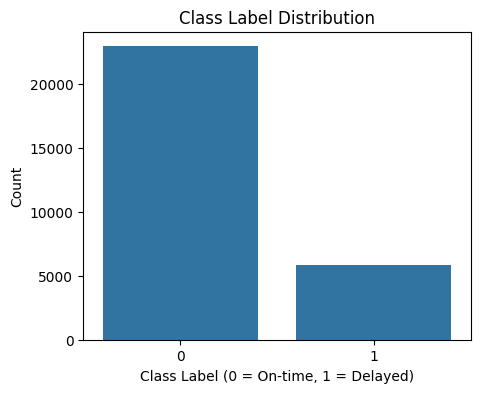

In [26]:
import seaborn as sns
import matplotlib.pyplot as plt

# Check distribution
print(df['DELAYED'].value_counts())
print("\nPercentage distribution:")
print(df['DELAYED'].value_counts(normalize=True) * 100)

# Visualization
plt.figure(figsize=(5,4))
sns.countplot(x=df['DELAYED'])
plt.title("Class Label Distribution")
plt.xlabel("Class Label (0 = On-time, 1 = Delayed)")
plt.ylabel("Count")
plt.show()


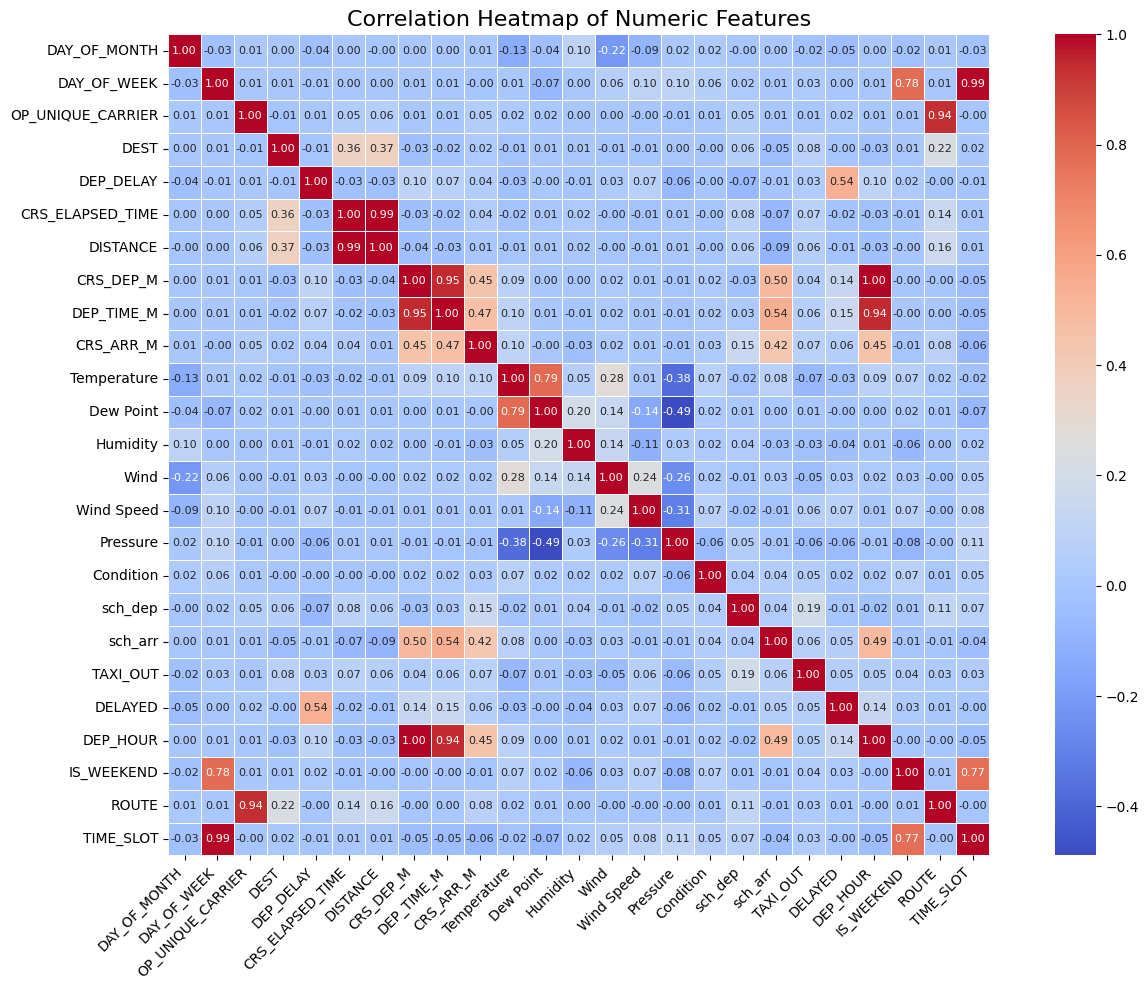

In [34]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Select numeric columns
num_cols = df.select_dtypes(include=['int64', 'float64']).columns

# Compute correlation
corr = df[num_cols].corr()

# Create a mask (hide upper triangle for cleaner view)
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(14, 10))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    square=True,
    linewidths=0.5,
    cbar=True,
    annot_kws={"size": 8}      # clean numeric text
)

plt.title("Correlation Heatmap of Numeric Features", fontsize=16)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


save data

In [59]:
df.to_csv("preproces_data.csv", index=False)


